# Feature Extraction and Feature Analysis

Simple study notes using the sample code from `docs/FeatureExtraction.pdf`.
Run the cells in order. Each exercise keeps the PDF's objective and tasks, followed by its sample implementation and short analysis answers. The task lists also include experiments to try by changing the shown parameters; this notebook focuses on the supplied examples.

## Setup

The default image is `images/building.jpg`. Change the filename below to use another image.

In [1]:
from pathlib import Path
import time

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import skew, entropy
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops, hog
from sklearn.svm import SVC
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

In [2]:
def display_images(images, columns=2, figsize=(8, 10)):
    rows = (len(images) + columns - 1) // columns
    plt.figure(figsize=figsize)

    for i, (title, image) in enumerate(images.items(), start=1):
        plt.subplot(rows, columns, i)
        plt.imshow(image, cmap="gray")
        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

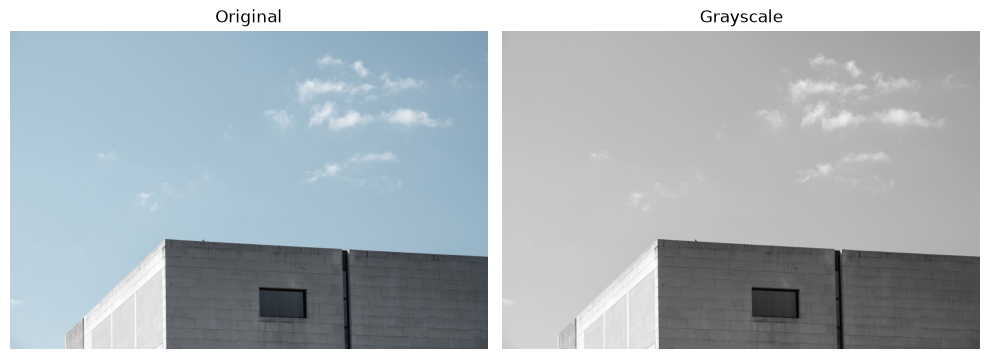

In [3]:
img = cv.imread("../images/building.jpg")
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

images = {"Original": cv.cvtColor(img, cv.COLOR_BGR2RGB), "Grayscale": gray}
display_images(images, columns=2, figsize=(10, 4))

### 1. Pixel, Intensity and Histogram Features

**Objective:** Understand raw pixel values and global intensity statistics as the simplest features.

**Tasks:**

- Load an image, convert to grayscale, and resize to a fixed size.
- Flatten the pixels into a feature vector and report its dimension.
- Compute the mean, standard deviation, skewness and entropy of intensities.
- Plot and compare grayscale histograms (32 and 256 bins) for different images.
- Apply histogram equalization and compare before and after.

Resize → flatten → compute intensity statistics → equalize the histogram. A 64 × 64 image gives 4,096 raw features. Entropy here is measured in nats.

In [4]:
small = cv.resize(gray, (64, 64))
raw_feature = small.flatten()
print("Raw feature dimension:", raw_feature.shape)

Raw feature dimension: (4096,)


In [5]:
hist = cv.calcHist([gray], [0], None, [256], [0, 256]).ravel()
hist_norm = hist / hist.sum()
stats = [gray.mean(), gray.std(), skew(gray.ravel()), entropy(hist_norm + 1e-12)]
print("Mean, Std, Skewness, Entropy:", stats)

Mean, Std, Skewness, Entropy: [np.float64(167.3680098470052), np.float64(45.417336379777794), np.float64(-1.129653946389325), np.float32(4.4843426)]


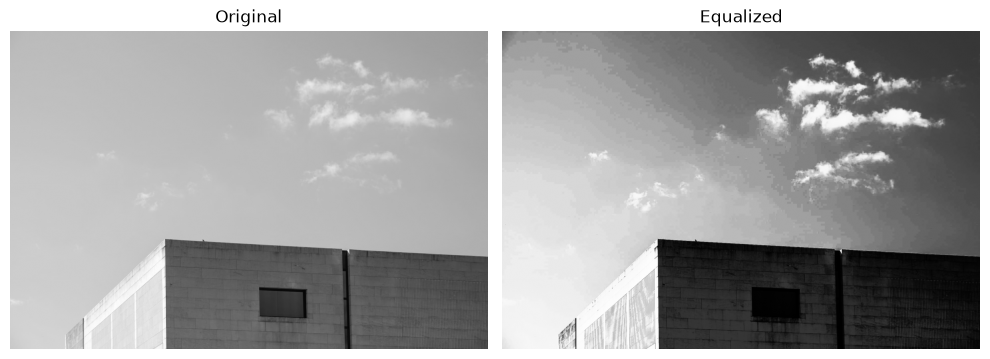

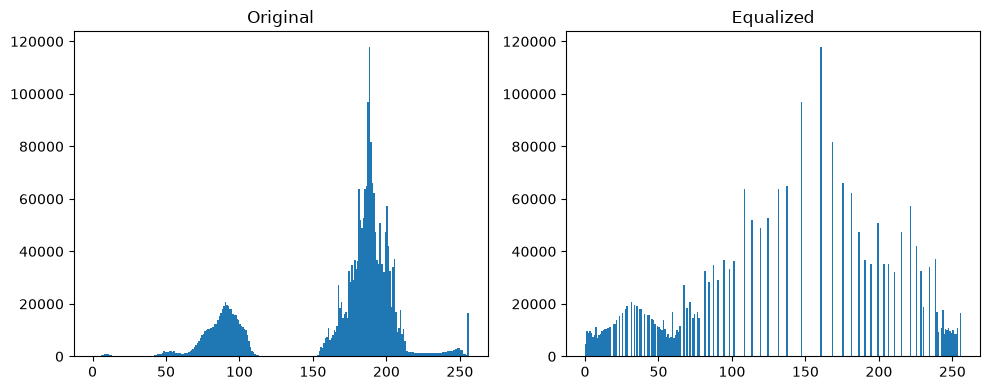

In [6]:
eq = cv.equalizeHist(gray)
images = {"Original": gray, "Equalized": eq}
display_images(images, columns=2, figsize=(10, 4))

plt.figure(figsize=(10, 4))
for i, (title, image) in enumerate(images.items(), start=1):
    plt.subplot(1, 2, i)
    plt.hist(image.ravel(), bins=256, range=(0, 256))
    plt.title(title)

plt.tight_layout()
plt.show()

#### Why are raw pixels a poor feature under shifts, rotation, or lighting change?

Raw pixels depend on position and brightness. Shifting or rotating an object moves values to different vector entries; lighting changes the values themselves.

#### Which statistic best separates a dark image from a bright one?

Mean intensity. A bright image usually has a higher mean than a dark image.

### 2. Color Features

**Objective:** Extract and compare color descriptors across color spaces.

**Tasks:**

- Compute 3D color histograms in RGB and HSV.
- Compute color moments (mean, std, skewness per channel) to get a 9-value descriptor.
- Compare images using correlation, chi-square, intersection and Bhattacharyya histogram distances.
- Test robustness by changing the brightness of an image.

Convert to HSV → compute a 512-value histogram → compute 9 color moments → compare histograms. The PDF compares the blue channel before and after a brightness increase.

In [7]:
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
h = cv.calcHist([hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256])
h = cv.normalize(h, h).flatten()

In [8]:
def color_moments(image):
    feats = []
    for c in cv.split(image):
        c = c.astype(float).ravel()
        feats += [c.mean(), c.std(), skew(c)]
    return np.array(feats)


print(color_moments(hsv))

[ 98.71310181  19.99109596  -4.54386603  44.18716756  16.80097202
  -0.22160363 184.89599569  50.48286175  -1.33265505]


In [9]:
bright = cv.convertScaleAbs(img, alpha=1, beta=50)
h1 = cv.calcHist([img], [0], None, [64], [0, 256])
h2 = cv.calcHist([bright], [0], None, [64], [0, 256])
for name, m in [
    ("Correlation", cv.HISTCMP_CORREL),
    ("Chi-square", cv.HISTCMP_CHISQR),
    ("Intersection", cv.HISTCMP_INTERSECT),
    ("Bhattacharyya", cv.HISTCMP_BHATTACHARYYA),
]:
    print(name, cv.compareHist(h1, h2, m))

Correlation -0.0623229856470882
Chi-square 319662583.1556184
Intersection 111514.0
Bhattacharyya 0.8877406213829874


#### Which color space is more stable under illumination change, RGB or HSV?

HSV separates brightness (V) from hue and saturation, so H and S can be more stable. A full HSV histogram still includes V and is not illumination invariant.

#### How does the number of bins affect descriptor size and discriminative power?

More bins capture finer differences but increase size and sensitivity to noise. With b bins per channel, a 3D histogram has b³ values.

### 3. Edge and Gradient Features

**Objective:** Use gradients and edges as features and study their sensitivity to noise.

**Tasks:**

- Apply Sobel, Prewitt, Laplacian and Canny to the same image.
- Add Gaussian noise and repeat; compare with and without Gaussian smoothing.
- Compute gradient magnitude and orientation, and build an orientation histogram.
- Vary the Canny thresholds and sigma, and tabulate edge pixel counts.

Smooth → compute gradients → get magnitude and orientation → detect edges. The sample uses Sobel, Laplacian and Canny; Prewitt and noise tests are additional tasks in the PDF.

In [10]:
blur = cv.GaussianBlur(gray, (5, 5), 1.4)
gx = cv.Sobel(blur, cv.CV_64F, 1, 0, ksize=3)
gy = cv.Sobel(blur, cv.CV_64F, 0, 1, ksize=3)
mag = np.sqrt(gx**2 + gy**2)
ang = np.degrees(np.arctan2(gy, gx)) % 180

lap = cv.Laplacian(blur, cv.CV_64F)
canny = cv.Canny(blur, 100, 200)

orient_hist, _ = np.histogram(ang, bins=9, range=(0, 180), weights=mag)
print("Edge orientation histogram:", orient_hist / max(orient_hist.sum(), 1e-12))

Edge orientation histogram: [0.19852786 0.06042009 0.07833678 0.06809319 0.25782495 0.07625864
 0.06010993 0.05343438 0.14699418]


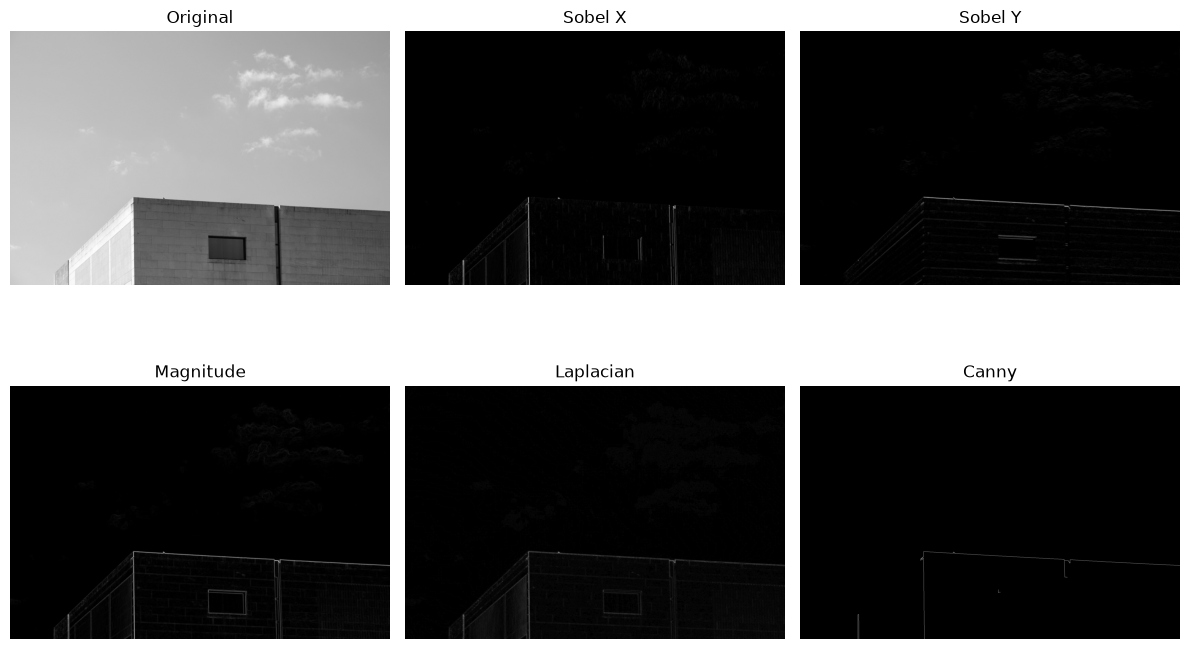

In [11]:
images = {
    "Original": gray,
    "Sobel X": np.abs(gx),
    "Sobel Y": np.abs(gy),
    "Magnitude": mag,
    "Laplacian": np.abs(lap),
    "Canny": canny,
}
display_images(images, columns=3, figsize=(12, 8))

#### Why does the Laplacian amplify noise more than Sobel?

The Laplacian is a second derivative, which emphasizes rapid changes and noise more strongly than the first derivatives used by Sobel. Smoothing reduces this effect.

#### How would you choose Canny thresholds automatically (for example from the median intensity)?

A simple heuristic sets the thresholds to 0.67 × median intensity and 1.33 × median intensity, clipped to [0, 255]. Tune them for the image: intensity is only a proxy for the gradients thresholded by Canny.

### 4. Shape Features

**Objective:** Describe objects by their contours and shape moments.

**Tasks:**

- Segment objects using Otsu thresholding and find contours.
- Compute area, perimeter, aspect ratio, extent, solidity and circularity for each contour.
- Compute Hu moments (7 values) and test their invariance to rotation and scale.
- Match shapes with cv2.matchShapes.

Threshold → find contours → measure each contour. Extent is added to the PDF sample as area divided by bounding-box area. Small contours are ignored.

In [12]:
_, bw = cv.threshold(gray, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)
contours, _ = cv.findContours(bw, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

In [13]:
for c in contours:
    area = cv.contourArea(c)
    if area < 100:
        continue
    perim = cv.arcLength(c, True)
    x, y, w, h = cv.boundingRect(c)
    hull_area = cv.contourArea(cv.convexHull(c))
    circularity = 4 * np.pi * area / (perim**2)
    extent = area / (w * h)
    solidity = area / hull_area
    hu = cv.HuMoments(cv.moments(c)).flatten()
    hu_log = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)
    print("Area, perimeter, aspect ratio, extent, circularity, solidity:")
    print(area, perim, w / h, extent, circularity, solidity)
    print("Hu moments (log):", hu_log)

Area, perimeter, aspect ratio, extent, circularity, solidity:
248.5 333.0710676908493 0.03225806451612903 0.501008064516129 0.02814896549253491 0.6743554952510177
Hu moments (log): [-0.38162111 -0.761048    0.68492405  0.68581379  1.37118272  0.30569137
 -6.88971433]
Area, perimeter, aspect ratio, extent, circularity, solidity:
522947.5 3478.9777026176453 2.9411764705882355 0.9101070309780717 0.5429560348662748 0.9861407852580724
Hu moments (log): [0.53411664 1.24028637 3.81621228 4.31998722 8.3886177  4.9416828
 9.69429284]


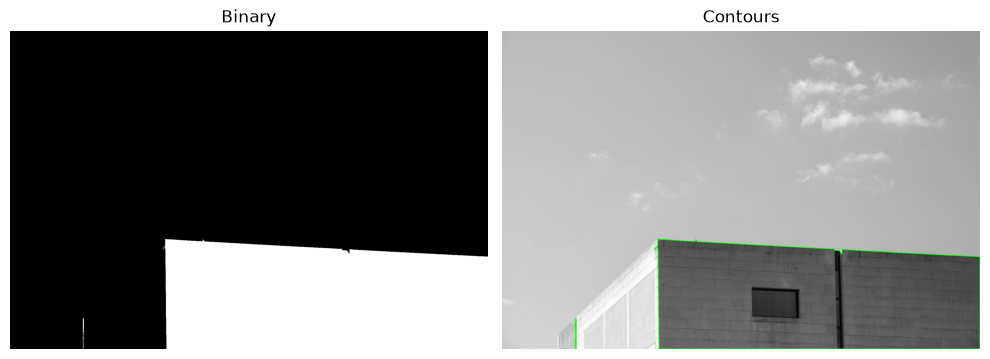

In [14]:
contourImage = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
cv.drawContours(contourImage, contours, -1, (0, 255, 0), 2)
display_images({"Binary": bw, "Contours": contourImage}, columns=2, figsize=(10, 4))

#### Which shape features are scale invariant? Rotation invariant?

Circularity, solidity and Hu moments are invariant to uniform scale and rotation in ideal geometry. Axis-aligned aspect ratio and extent are scale invariant but can change with rotation. Area and perimeter change with scale.

#### Why are Hu moments usually shown on a log scale?

Hu moments can differ by many orders of magnitude. A signed log makes them easier to compare; the small added constant avoids log(0).

### 5. Texture Features (LBP and GLCM)

**Objective:** Quantify texture using statistical and local pattern methods.

**Tasks:**

- Compute LBP histograms with different radius and number of points.
- Build GLCMs at several distances and angles; compute contrast, correlation, energy and homogeneity.
- Compare smooth, rough and regular textures (for example Brodatz or KTH-TIPS).

LBP describes local intensity patterns. GLCM counts neighboring intensity pairs at selected distances and angles.

In [15]:
P, R = 8, 1
lbp = local_binary_pattern(gray, P, R, method="uniform")
lbp_hist, _ = np.histogram(lbp, bins=P + 2, range=(0, P + 2), density=True)


print("LBP histogram:", lbp_hist)

LBP histogram: [0.00323853 0.01585775 0.00514974 0.03790283 0.04518026 0.12791911
 0.02391073 0.02907389 0.68475464 0.02701253]


In [16]:
glcm = graycomatrix(
    gray,
    distances=[1, 3],
    angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
    levels=256,
    symmetric=True,
    normed=True,
)
for prop in ["contrast", "correlation", "energy", "homogeneity"]:
    print(prop, graycoprops(glcm, prop).mean())

contrast 60.74095698347752
correlation 0.9852745015800735
energy 0.10740715884979887
homogeneity 0.7747157888078644


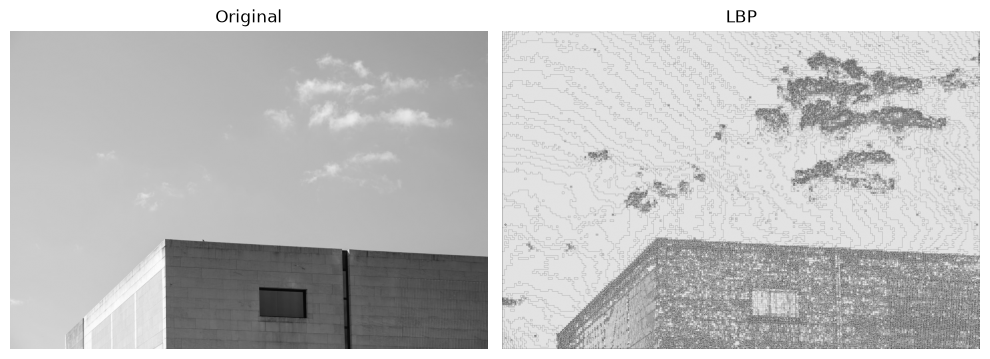

In [17]:
display_images({"Original": gray, "LBP": lbp}, columns=2, figsize=(10, 4))

#### What does the 'uniform' LBP mode do, and why does it shorten the histogram?

Uniform patterns have at most two circular bit transitions. This mode groups them by the number of one bits, with one extra bin for nonuniform patterns: P + 2 bins instead of up to 2ᴾ.

#### Which GLCM property separates smooth from rough texture best?

Contrast is often useful: smooth textures usually have low neighboring intensity differences, while rough textures have larger ones. The result depends on distance, angle and texture.

### 6. Corner Detection

**Objective:** Detect interest points and measure their stability.

**Tasks:**

- Apply Harris, Shi-Tomasi (goodFeaturesToTrack) and FAST.
- Test on rotated, scaled and blurred versions of the same image.
- Compute a simple repeatability score: the fraction of keypoints found again after transformation.

Apply the three detectors and count their responses. The PDF counts thresholded Harris response pixels; these are not individually suppressed corner points.

In [18]:
harris = cv.cornerHarris(np.float32(gray), blockSize=2, ksize=3, k=0.04)
harris_pts = np.argwhere(harris > 0.01 * harris.max())

shi = cv.goodFeaturesToTrack(gray, maxCorners=200, qualityLevel=0.01, minDistance=10)

fast = cv.FastFeatureDetector_create(threshold=30)
fast_kp = fast.detect(gray, None)
print("Harris response pixels:", len(harris_pts))
print("Shi-Tomasi corners:", 0 if shi is None else len(shi))
print("FAST keypoints:", len(fast_kp))

Harris response pixels: 325
Shi-Tomasi corners: 200
FAST keypoints: 201


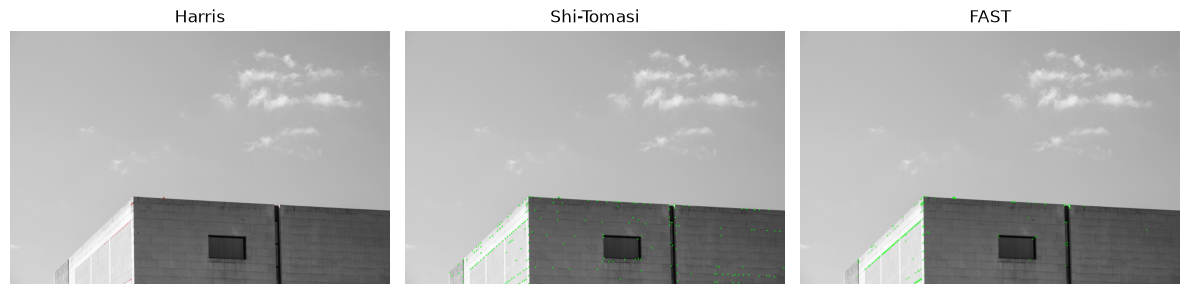

In [19]:
harrisImage = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
harrisImage[harris > 0.01 * harris.max()] = [255, 0, 0]

shiImage = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
if shi is not None:
    for point in shi:
        x, y = point.ravel().astype(int)
        cv.circle(shiImage, (x, y), 3, (0, 255, 0), -1)

fastImage = cv.drawKeypoints(gray, fast_kp, None, color=(0, 255, 0))
images = {"Harris": harrisImage, "Shi-Tomasi": shiImage, "FAST": fastImage}
display_images(images, columns=3, figsize=(12, 4))

#### Which detector is fastest, and which is most repeatable under rotation and scale?

FAST is usually fastest. Repeatability depends on the image and settings; these fixed-scale configurations do not provide full scale invariance. The sample detects corners but does not benchmark repeatability.

#### Why is Harris rotation invariant but not scale invariant?

Rotation preserves the eigenvalues used in the Harris response. Scaling changes the structure inside its fixed-size window, so scale selection or an image pyramid is needed.

### 7. SIFT (Scale-Invariant Feature Transform)

**Objective:** Detect and describe scale- and rotation-invariant keypoints, and match them between images.

**Tasks:**

- Create a SIFT detector and extract keypoints and 128-dimensional descriptors.
- Draw rich keypoints to see scale and orientation.
- Match using brute force and FLANN, then apply Lowe's ratio test (0.75).
- Estimate a homography with RANSAC and locate the object in a scene.
- Vary nfeatures, contrastThreshold and sigma; record keypoint count and matching quality.

Detect → describe → match → ratio test → RANSAC. For a runnable example, match the input against a rotated copy. To use a real object/scene pair, replace `img1` and `img2` with grayscale `cv.imread` calls.

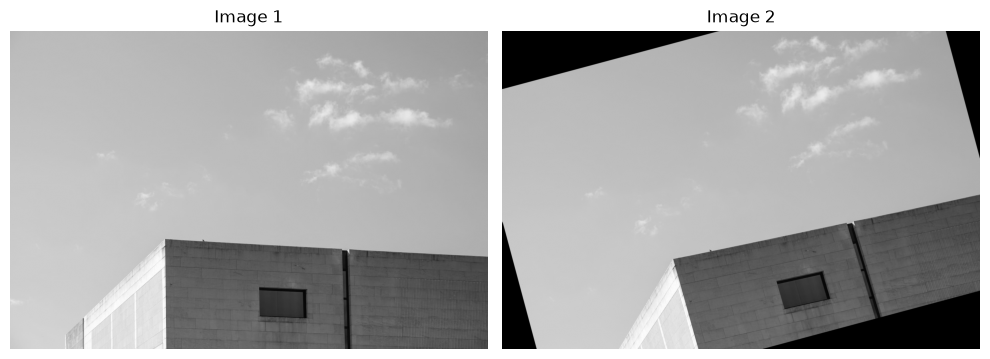

In [20]:
img1 = gray.copy()
angle = 15
scale = 1.0
h, w = gray.shape
M = cv.getRotationMatrix2D((w / 2, h / 2), angle, scale)
img2 = cv.warpAffine(img1, M, (w, h))

display_images({"Image 1": img1, "Image 2": img2}, columns=2, figsize=(10, 4))

In [21]:
sift = cv.SIFT_create(nfeatures=0, contrastThreshold=0.04, edgeThreshold=10, sigma=1.6)
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)
print("Keypoints:", len(kp1), len(kp2), "Descriptor shape:", des1.shape)

Keypoints: 236 322 Descriptor shape: (236, 128)


In [22]:
# FLANN matcher (KD-tree) with ratio test
flann = cv.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))
knn = flann.knnMatch(des1, des2, k=2)
good = []
for pair in knn:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good.append(m)
print("Good matches:", len(good))

Good matches: 117


Inliers: 104


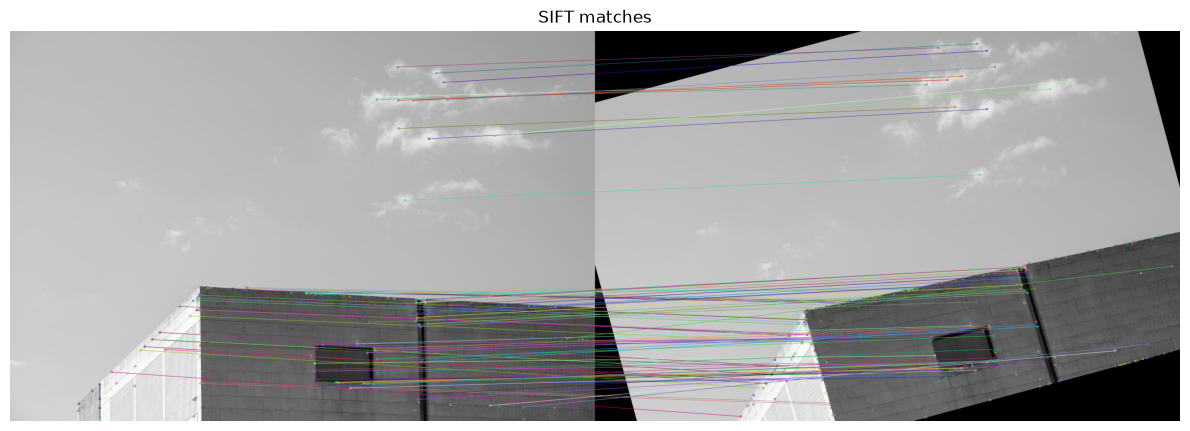

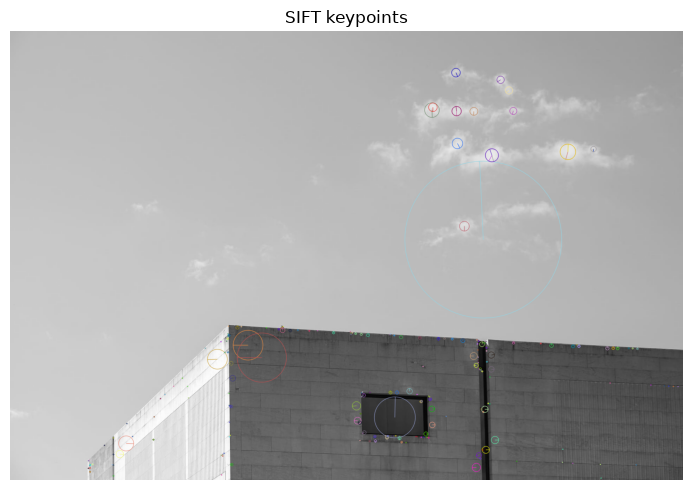

In [23]:
# Homography with RANSAC
if len(good) >= 4:
    src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)

    if mask is not None:
        print("Inliers:", int(mask.sum()))
        vis = cv.drawMatches(
            img1, kp1, img2, kp2, good, None, matchesMask=mask.ravel().tolist()
        )
        display_images({"SIFT matches": vis}, columns=1, figsize=(12, 5))

vis_kp = cv.drawKeypoints(
    img1, kp1, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
display_images({"SIFT keypoints": vis_kp}, columns=1, figsize=(8, 5))

#### What are the four main stages of SIFT (scale-space extrema, keypoint localization, orientation assignment, descriptor)?

1. Find scale-space extrema.
2. Refine keypoint locations and reject unstable points.
3. Assign orientations.
4. Build 128-value gradient descriptors.

#### Why is the ratio test needed, and what happens if the ratio is 0.5 or 0.9?

The ratio test rejects ambiguous matches whose two nearest neighbors are similarly close. A ratio of 0.5 is stricter and keeps fewer matches; 0.9 is more permissive and may keep more outliers.

#### How does contrastThreshold change the number of keypoints?

A higher threshold rejects more low-contrast points, usually reducing the keypoint count. A lower threshold retains more weak points and can increase noise sensitivity.

#### Test the same image rotated by 45 degrees and scaled by 0.5. How many matches survive?

The count depends on the image. Change `angle` to 45 and `scale` to 0.5 in the image-pair cell, then rerun SIFT and matching. `len(good)` reports surviving ratio-test matches; the RANSAC cell reports inliers.

### 8. ORB (Oriented FAST and Rotated BRIEF)

**Objective:** Use a fast binary descriptor and understand how it differs from SIFT.

**Tasks:**

- Create an ORB detector and extract keypoints and 32-byte binary descriptors.
- Match using brute force with Hamming distance and cross-check or the ratio test.
- Vary nfeatures, scaleFactor and nlevels.
- Use ORB matching for image stitching or simple object tracking in a short video.

Detect ORB keypoints → compute binary descriptors → match using Hamming distance. Reuse the same two images from SIFT. Cross-check keeps mutual nearest matches.

In [24]:
orb = cv.ORB_create(nfeatures=1000, scaleFactor=1.2, nlevels=8)
kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)
print("Descriptor shape:", des1.shape, "dtype:", des1.dtype)  # (N, 32), uint8

Descriptor shape: (795, 32) dtype: uint8


Matches: 476


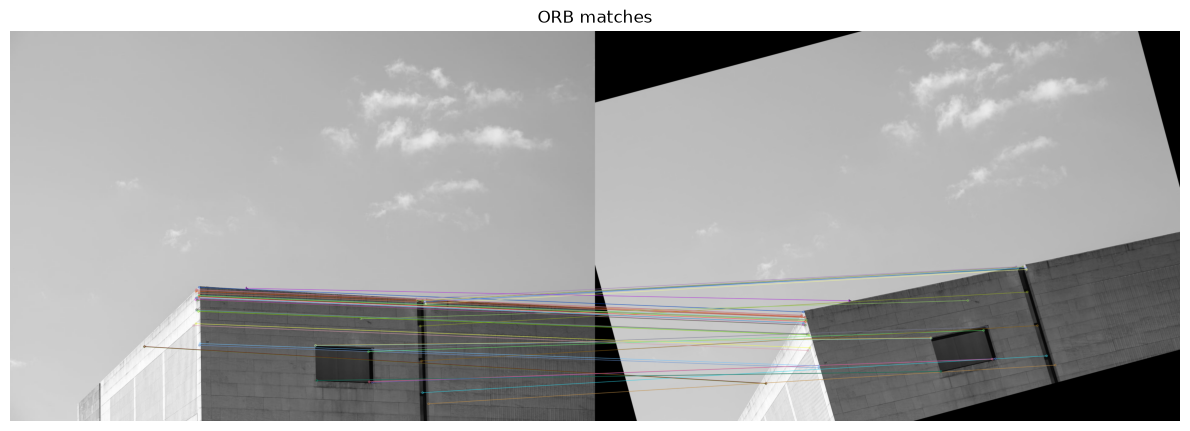

In [25]:
bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
matches = sorted(bf.match(des1, des2), key=lambda m: m.distance)
print("Matches:", len(matches))

vis = cv.drawMatches(
    img1,
    kp1,
    img2,
    kp2,
    matches[:50],
    None,
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
)
display_images({"ORB matches": vis}, columns=1, figsize=(12, 5))

#### Why use Hamming distance for ORB but Euclidean (L2) distance for SIFT?

ORB stores binary tests, so Hamming distance counts differing bits. SIFT stores numerical gradient histograms, so L2 distance compares their values.

#### How does ORB add rotation invariance to BRIEF, and what does it do about scale?

ORB estimates orientation from the intensity centroid and rotates the BRIEF sampling pattern. An image pyramid handles a limited range of scales.

#### What are the memory and speed benefits of binary descriptors?

Default ORB uses 32 bytes per descriptor; float32 SIFT uses 512 bytes. Binary matching uses fast XOR and bit-count operations, reducing storage and comparison cost.

### 9. SIFT vs ORB Comparison

**Objective:** Compare detectors and descriptors quantitatively.

**Tasks:**

- Create transformed copies: rotations (15, 45, 90 degrees), scales (0.5, 0.75, 1.5), Gaussian blur, noise and brightness change.
- For each transformation, record keypoint counts, extraction time, good matches and RANSAC inlier ratio for SIFT and ORB.
- Tabulate and plot the results.

The PDF compares one 45-degree rotation. The returned values are source keypoint count, good-match count and extraction time in seconds. Matching time is excluded. Change the transformation to try other conditions.

In [26]:
def evaluate(detector, norm, img, transformed, ratio=0.75):
    t0 = time.time()
    k1, d1 = detector.detectAndCompute(img, None)
    k2, d2 = detector.detectAndCompute(transformed, None)
    t = time.time() - t0
    bf = cv.BFMatcher(norm)
    if d1 is None or d2 is None or len(d2) < 2:
        return len(k1), 0, t
    knn = bf.knnMatch(d1, d2, k=2)
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    return len(k1), len(good), t

In [27]:
h, w = gray.shape
M = cv.getRotationMatrix2D((w / 2, h / 2), 45, 1.0)
rot = cv.warpAffine(gray, M, (w, h))
print("SIFT:", evaluate(cv.SIFT_create(), cv.NORM_L2, gray, rot))
print("ORB :", evaluate(cv.ORB_create(1000), cv.NORM_HAMMING, gray, rot))

SIFT: (236, 109, 0.3914058208465576)
ORB : (795, 327, 0.025121688842773438)


#### Which method is more robust to scale change? To blur? To rotation?

SIFT is generally stronger under large scale changes. Both handle rotation, and blur can weaken both. The simple PDF comparison tests one rotation; use different transformed inputs to compare other conditions.

#### When would you choose ORB over SIFT (real-time, embedded devices) and when SIFT over ORB (accuracy)?

Choose ORB for speed and low memory, such as real-time or embedded work. Choose SIFT when matching robustness matters more than computation and storage.

### 10. HOG (Histogram of Oriented Gradients)

**Objective:** Use a dense gradient descriptor for object recognition.

**Tasks:**

- Extract HOG features and visualize them.
- Vary cell size, block size and number of orientations; record descriptor length.
- Train an SVM on HOG features for digit or pedestrian classification.
- Run OpenCV's built-in HOG people detector on sample images.

Extract and visualize gradient histograms, then train an SVM on the bundled digit dataset. The final cell uses OpenCV's separate pretrained people detector.

HOG length: (1368036,)


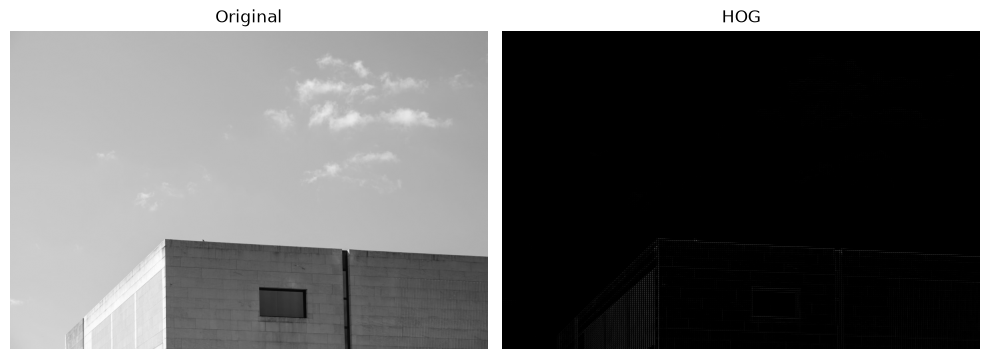

In [28]:
feat, hog_img = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    block_norm="L2-Hys",
)
print("HOG length:", feat.shape)


display_images({"Original": gray, "HOG": hog_img}, columns=2, figsize=(10, 4))

In [29]:
digits = load_digits()
X = np.array(
    [
        hog(im, orientations=9, pixels_per_cell=(4, 4), cells_per_block=(2, 2))
        for im in digits.images
    ]
)
Xtr, Xte, ytr, yte = train_test_split(X, digits.target, test_size=0.3, random_state=0)
print("SVM accuracy:", SVC(kernel="rbf").fit(Xtr, ytr).score(Xte, yte))

SVM accuracy: 0.8851851851851852


People detections: 1


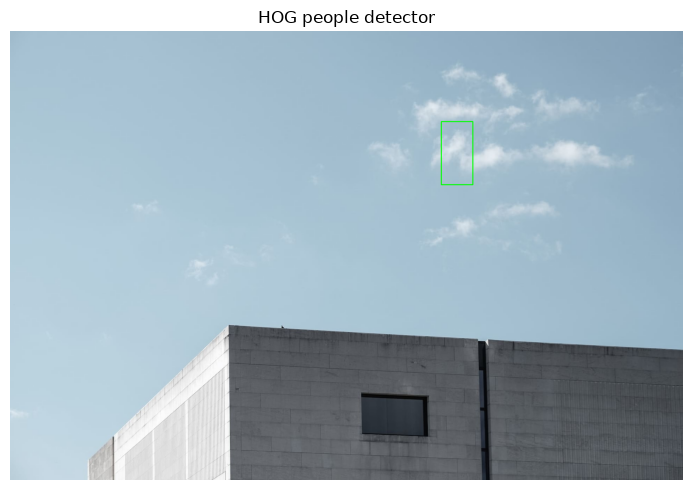

In [30]:
hog_cv = cv.HOGDescriptor()
hog_cv.setSVMDetector(cv.HOGDescriptor_getDefaultPeopleDetector())
rects, _ = hog_cv.detectMultiScale(img, winStride=(8, 8), padding=(8, 8), scale=1.05)

peopleImage = cv.cvtColor(img, cv.COLOR_BGR2RGB)
for x, y, w, h in rects:
    cv.rectangle(peopleImage, (x, y), (x + w, y + h), (0, 255, 0), 2)

print("People detections:", len(rects))
display_images({"HOG people detector": peopleImage}, columns=1, figsize=(8, 5))

#### How does cell size trade off detail against feature dimension?

Smaller cells preserve finer detail but create more features. Larger cells reduce descriptor size but lose small structures.

#### Why is block normalization important?

Block normalization reduces sensitivity to local brightness and contrast. Overlapping blocks describe each cell in several local contexts.